# Gianfranco Godoy - Dias Maximiliano

# TP7: Introducción a Databricks y procesamiento de datos con Apache Spark
**Materia:** Análisis de datos en la nube

## Resumen del proceso y resultados
**Dataset:** 30 clubes del fútbol argentino (equipo, ciudad, provincia, año de fundación y estadio) más una tabla auxiliar de provincias y regiones. Ambos archivos CSV se cargaron en un Volume de Databricks.

**Proceso seguido:**
1. **Entorno:** se creó el notebook en Databricks Free Edition, conectado a cómputo serverless.
2. **Carga y exploración:** se leyó el CSV con Spark (32 filas, 5 columnas) y se exploró con Spark SQL.
3. **Transformaciones:** se eliminaron 2 duplicados y se trataron los nulos (1 fila eliminada, el resto reemplazado por "Sin dato"). Se crearon las columnas `antiguedad` y `epoca`, se aplicaron filtros, agregaciones y un join con la tabla de regiones. Quedaron 29 filas.
4. **Delta Lake:** se guardó el resultado en formato Delta y se validó la integridad (misma cantidad de filas, mismos nombres y tipos, 0 filas distintas).
5. **Visualización:** se graficaron los clubes por provincia, por década de fundación y la antigüedad promedio por región.

**Resultados principales:** Buenos Aires, CABA y Santa Fe concentran 21 de los 29 clubes, la década de 1900 es la de mayor cantidad de fundaciones (16 clubes) y la región Centro tiene la mayor antigüedad promedio (119,4 años).

## Etapa 1: Configuración del entorno
Se creó una cuenta en Databricks Free Edition. Esta edición trabaja con cómputo serverless, por lo que no se crea un clúster manualmente. Se creó este notebook y se probaron comandos simples en Python y SQL.

In [0]:
print("Hola Databricks")

Hola Databricks


In [0]:
%sql
SELECT current_date() AS hoy

hoy
2026-11-02


## Etapa 2: Carga y exploración de datos
**Dataset elegido:** equipos del fútbol argentino (equipos_futbol_argentino.csv), con equipo, ciudad, provincia, año de fundación y estadio. Se cargó en un Volume de Databricks (`tp_volume`).

In [0]:
# Listar los archivos que hay en el Volume
display(dbutils.fs.ls("/Volumes/workspace/default/tp_volume/"))

path,name,size,modificationTime
dbfs:/Volumes/workspace/default/tp_volume/equipos_delta/,equipos_delta/,0,1793648504016
dbfs:/Volumes/workspace/default/tp_volume/equipos_futbol_argentino.csv,equipos_futbol_argentino.csv,1494,1793628356000
dbfs:/Volumes/workspace/default/tp_volume/provincias_regiones.csv,provincias_regiones.csv,164,1793628356000


In [0]:
# Ruta del archivo de equipos en el Volume
ruta_equipos = "/Volumes/workspace/default/tp_volume/equipos_futbol_argentino.csv"

# Leer el CSV con Spark: la primera fila es el encabezado y Spark detecta los tipos de datos
df = (spark.read
      .option("header", True)
      .option("inferSchema", True)
      .csv(ruta_equipos))

# Mostrar las primeras 5 filas
df.show(5)

+-------------+------------+------------+--------------+--------------------+
|       equipo|      ciudad|   provincia|anio_fundacion|             estadio|
+-------------+------------+------------+--------------+--------------------+
| Boca Juniors|Buenos Aires|        CABA|          1905|        La Bombonera|
|  River Plate|Buenos Aires|        CABA|          1901|          Monumental|
|  Racing Club|  Avellaneda|Buenos Aires|          1903|    Presidente Perón|
|Independiente|  Avellaneda|Buenos Aires|          1905|Libertadores de A...|
|  San Lorenzo|Buenos Aires|        CABA|          1908|     Nuevo Gasómetro|
+-------------+------------+------------+--------------+--------------------+
only showing top 5 rows


In [0]:
# Estructura del DataFrame: nombre y tipo de cada columna
df.printSchema()

# Cantidad total de filas
print("Cantidad de filas:", df.count())

root
 |-- equipo: string (nullable = true)
 |-- ciudad: string (nullable = true)
 |-- provincia: string (nullable = true)
 |-- anio_fundacion: integer (nullable = true)
 |-- estadio: string (nullable = true)

Cantidad de filas: 32


In [0]:
# Registrar el DataFrame como vista para consultarlo con SQL
df.createOrReplaceTempView("equipos")

In [0]:
%sql
SELECT * FROM equipos LIMIT 10;


equipo,ciudad,provincia,anio_fundacion,estadio
Boca Juniors,Buenos Aires,CABA,1905,La Bombonera
River Plate,Buenos Aires,CABA,1901,Monumental
Racing Club,Avellaneda,Buenos Aires,1903,Presidente Perón
Independiente,Avellaneda,Buenos Aires,1905,Libertadores de América
San Lorenzo,Buenos Aires,CABA,1908,Nuevo Gasómetro
Estudiantes de La Plata,La Plata,Buenos Aires,null,null
Gimnasia y Esgrima La Plata,La Plata,Buenos Aires,1887,null
Vélez Sarsfield,Buenos Aires,CABA,1910,José Amalfitani
Newell's Old Boys,Rosario,Santa Fe,1903,null
Rosario Central,Rosario,Santa Fe,1889,null


In [0]:
%sql
SELECT provincia, COUNT(*) AS cantidad
FROM equipos
GROUP BY provincia
ORDER BY cantidad DESC;

provincia,cantidad
CABA,10
Buenos Aires,10
Santa Fe,4
Córdoba,2
Mendoza,2
Santiago del Estero,1
San Juan,1
Tucumán,1
null,1


In [0]:
%sql
SELECT equipo, anio_fundacion
FROM equipos
WHERE anio_fundacion IS NOT NULL
ORDER BY anio_fundacion ASC
LIMIT 5;

equipo,anio_fundacion
Gimnasia y Esgrima La Plata,1887
Rosario Central,1889
Banfield,1896
River Plate,1901
Tigre,1902


### Observaciones de la exploración
- El dataset tiene 32 filas y 5 columnas: equipo, ciudad, provincia, anio_fundacion y estadio.
- `anio_fundacion` se leyó como entero, por lo que se puede usar en cálculos.
- Se detectaron valores nulos en `anio_fundacion`, `provincia` y, sobre todo, en `estadio`.
- Hay filas duplicadas (por ejemplo Boca Juniors y San Lorenzo), que inflan los conteos por provincia.
- CABA y Buenos Aires concentran la mayor cantidad de clubes.
- Estos problemas se resuelven en la Etapa 3 (limpieza de datos).

## Etapa 3: Transformaciones de datos

### 3.1 Detección y eliminación de duplicados

In [0]:
from pyspark.sql import functions as F

# Cuántas filas están repetidas
total = df.count()
sin_duplicados = df.dropDuplicates().count()
print("Filas totales:", total)
print("Filas sin duplicados:", sin_duplicados)
print("Duplicados detectados:", total - sin_duplicados)

Filas totales: 32
Filas sin duplicados: 30
Duplicados detectados: 2


In [0]:
# Cantidad de nulos en cada columna
df.select([
    F.sum(F.col(c).isNull().cast("int")).alias(c)
    for c in df.columns
]).show()

+------+------+---------+--------------+-------+
|equipo|ciudad|provincia|anio_fundacion|estadio|
+------+------+---------+--------------+-------+
|     0|     0|        1|             1|     24|
+------+------+---------+--------------+-------+



In [0]:
# Eliminar filas completamente repetidas
df_limpio = df.dropDuplicates()
print("Filas después de eliminar duplicados:", df_limpio.count())

Filas después de eliminar duplicados: 30


### 3.2 Manejo de valores nulos
**Criterio aplicado:**
- `anio_fundacion` (1 nulo): se elimina la fila, porque es un dato clave para los cálculos (se descartó Estudiantes de La Plata).
- `provincia` (1 nulo) y `estadio` (24 nulos): se reemplazan por "Sin dato" para no perder clubes.

In [0]:
# 1) Eliminar filas sin año de fundación (dato clave para los cálculos)
df_limpio = df_limpio.dropna(subset=["anio_fundacion"])

# 2) Reemplazar nulos de provincia y estadio por un valor por defecto
df_limpio = df_limpio.fillna({"provincia": "Sin dato", "estadio": "Sin dato"})

print("Filas después de manejar nulos:", df_limpio.count())

Filas después de manejar nulos: 29


In [0]:
# Verificar que no quedaron nulos
df_limpio.select([
    F.sum(F.col(c).isNull().cast("int")).alias(c)
    for c in df_limpio.columns
]).show()

+------+------+---------+--------------+-------+
|equipo|ciudad|provincia|anio_fundacion|estadio|
+------+------+---------+--------------+-------+
|     0|     0|        0|             0|      0|
+------+------+---------+--------------+-------+



### 3.3 Columnas calculadas y filtros

In [0]:
# Antigüedad del club en años (usamos 2026 como año actual)
df_t = df_limpio.withColumn("antiguedad", 2026 - F.col("anio_fundacion"))

# Clasificar por época de fundación
df_t = df_t.withColumn(
    "epoca",
    F.when(F.col("anio_fundacion") < 1900, "Siglo XIX")
     .when(F.col("anio_fundacion") < 1910, "1900-1909")
     .otherwise("1910 en adelante")
)

df_t.select("equipo", "anio_fundacion", "antiguedad", "epoca").show(10)

+--------------------+--------------+----------+----------------+
|              equipo|anio_fundacion|antiguedad|           epoca|
+--------------------+--------------+----------+----------------+
|            Belgrano|          1905|       121|       1900-1909|
|            Banfield|          1896|       130|       Siglo XIX|
|            Platense|          1905|       121|       1900-1909|
|    Atlético Tucumán|          1902|       124|       1900-1909|
|Gimnasia y Esgrim...|          1887|       139|       Siglo XIX|
|               Unión|          1907|       119|       1900-1909|
|               Colón|          1905|       121|       1900-1909|
|   Newell's Old Boys|          1903|       123|       1900-1909|
|     Vélez Sarsfield|          1910|       116|1910 en adelante|
|         River Plate|          1901|       125|       1900-1909|
+--------------------+--------------+----------+----------------+
only showing top 10 rows


In [0]:
# Clubes fundados antes de 1905
df_t.filter(F.col("anio_fundacion") < 1905) \
    .select("equipo", "anio_fundacion") \
    .orderBy("anio_fundacion") \
    .show()

# Clubes de la provincia de Buenos Aires con más de 100 años de antigüedad
df_t.filter((F.col("provincia") == "Buenos Aires") & (F.col("antiguedad") > 100)) \
    .select("equipo", "ciudad", "antiguedad") \
    .show()

+--------------------+--------------+
|              equipo|anio_fundacion|
+--------------------+--------------+
|Gimnasia y Esgrim...|          1887|
|     Rosario Central|          1889|
|            Banfield|          1896|
|         River Plate|          1901|
|    Atlético Tucumán|          1902|
|               Tigre|          1902|
|   Newell's Old Boys|          1903|
|         Racing Club|          1903|
|    Barracas Central|          1904|
|  Argentinos Juniors|          1904|
+--------------------+--------------+

+--------------------+-------------+----------+
|              equipo|       ciudad|antiguedad|
+--------------------+-------------+----------+
|            Banfield|     Banfield|       130|
|            Platense|Vicente López|       121|
|Gimnasia y Esgrim...|     La Plata|       139|
|               Lanús|        Lanús|       111|
|               Tigre|     Victoria|       124|
|           Sarmiento|        Junín|       115|
|         Racing Club|   Avellaneda

### 3.4 Agregaciones y join

In [0]:
# Cantidad de clubes y antigüedad promedio por provincia
por_provincia = (df_t.groupBy("provincia")
                 .agg(F.count("*").alias("cantidad_clubes"),
                      F.round(F.avg("antiguedad"), 1).alias("antiguedad_promedio"))
                 .orderBy(F.desc("cantidad_clubes")))

por_provincia.show()

+-------------------+---------------+-------------------+
|          provincia|cantidad_clubes|antiguedad_promedio|
+-------------------+---------------+-------------------+
|       Buenos Aires|              9|              119.4|
|               CABA|              8|              117.1|
|           Santa Fe|              4|              125.0|
|            Mendoza|              2|              109.0|
|            Córdoba|              2|              117.0|
|            Tucumán|              1|              124.0|
|Santiago del Estero|              1|              107.0|
|           San Juan|              1|              119.0|
|           Sin dato|              1|              108.0|
+-------------------+---------------+-------------------+



In [0]:
# Leer la tabla de provincias y regiones
ruta_prov = "/Volumes/workspace/default/tp_volume/provincias_regiones.csv"
df_prov = (spark.read
           .option("header", True)
           .option("inferSchema", True)
           .csv(ruta_prov))

# Unir ambas tablas por la columna provincia (left join: conserva todos los clubes)
df_final = df_t.join(df_prov, on="provincia", how="left")

df_final.select("equipo", "provincia", "region", "antiguedad").show(10)

+--------------------+------------+--------+----------+
|              equipo|   provincia|  region|antiguedad|
+--------------------+------------+--------+----------+
|            Belgrano|     Córdoba|  Centro|       121|
|            Banfield|Buenos Aires|  Centro|       130|
|            Platense|Buenos Aires|  Centro|       121|
|    Atlético Tucumán|     Tucumán|Noroeste|       124|
|Gimnasia y Esgrim...|Buenos Aires|  Centro|       139|
|               Unión|    Santa Fe|  Centro|       119|
|               Colón|    Santa Fe|  Centro|       121|
|   Newell's Old Boys|    Santa Fe|  Centro|       123|
|     Vélez Sarsfield|        CABA|  Centro|       116|
|         River Plate|        CABA|  Centro|       125|
+--------------------+------------+--------+----------+
only showing top 10 rows


In [0]:
# Cantidad de clubes y antigüedad promedio por región (usa el join)
por_region = (df_final.groupBy("region")
              .agg(F.count("*").alias("cantidad_clubes"),
                   F.round(F.avg("antiguedad"), 1).alias("antiguedad_promedio"))
              .orderBy(F.desc("cantidad_clubes")))

por_region.show()

+--------+---------------+-------------------+
|  region|cantidad_clubes|antiguedad_promedio|
+--------+---------------+-------------------+
|  Centro|             23|              119.4|
|    Cuyo|              3|              112.3|
|Noroeste|              2|              115.5|
|    NULL|              1|              108.0|
+--------+---------------+-------------------+



In [0]:
# Reemplazar región nula (clubes sin provincia) por un valor por defecto
df_final = df_final.fillna({"region": "Sin dato"})

df_final.printSchema()
print("Filas:", df_final.count())

root
 |-- provincia: string (nullable = false)
 |-- equipo: string (nullable = true)
 |-- ciudad: string (nullable = true)
 |-- anio_fundacion: integer (nullable = true)
 |-- estadio: string (nullable = false)
 |-- antiguedad: integer (nullable = true)
 |-- epoca: string (nullable = false)
 |-- region: string (nullable = false)

Filas: 29


## Etapa 4: Almacenamiento con Delta Lake

In [0]:
# Ruta donde se guarda la tabla Delta (dentro del Volume)
ruta_delta = "/Volumes/workspace/default/tp_volume/equipos_delta"

# Guardar los datos transformados en formato Delta
(df_final.write
    .format("delta")
    .mode("overwrite")
    .save(ruta_delta))

print("Datos guardados en formato Delta")

Datos guardados en formato Delta


In [0]:
# Leer nuevamente la tabla desde Delta Lake
df_delta = spark.read.format("delta").load(ruta_delta)
df_delta.show(5)

+------------+--------------------+--------------------+--------------+--------+----------+---------+--------+
|   provincia|              equipo|              ciudad|anio_fundacion| estadio|antiguedad|    epoca|  region|
+------------+--------------------+--------------------+--------------+--------+----------+---------+--------+
|     Córdoba|            Belgrano|             Córdoba|          1905|Sin dato|       121|1900-1909|  Centro|
|Buenos Aires|            Banfield|            Banfield|          1896|Sin dato|       130|Siglo XIX|  Centro|
|Buenos Aires|            Platense|       Vicente López|          1905|Sin dato|       121|1900-1909|  Centro|
|     Tucumán|    Atlético Tucumán|San Miguel de Tuc...|          1902|Sin dato|       124|1900-1909|Noroeste|
|Buenos Aires|Gimnasia y Esgrim...|            La Plata|          1887|Sin dato|       139|Siglo XIX|  Centro|
+------------+--------------------+--------------------+--------------+--------+----------+---------+--------+
o

In [0]:
# Comparar cantidad de filas, esquema y contenido
print("Filas originales:", df_final.count())
print("Filas en Delta:  ", df_delta.count())
print("Mismo esquema:   ", df_final.schema == df_delta.schema)
print("Filas distintas: ", df_final.exceptAll(df_delta).count())  # debe dar 0

Filas originales: 29
Filas en Delta:   29
Mismo esquema:    False
Filas distintas:  0


In [0]:
# Comparar nombres y tipos de columnas (sin tener en cuenta nullable)
print("Mismos nombres y tipos:", df_final.dtypes == df_delta.dtypes)

# Ver las diferencias de nullable, si las hay
for a, b in zip(df_final.schema.fields, df_delta.schema.fields):
    if a.nullable != b.nullable:
        print(f"{a.name}: original nullable={a.nullable}, delta nullable={b.nullable}")

Mismos nombres y tipos: True
provincia: original nullable=False, delta nullable=True
estadio: original nullable=False, delta nullable=True
epoca: original nullable=False, delta nullable=True
region: original nullable=False, delta nullable=True


**Validación de integridad:** la cantidad de filas, los nombres y tipos de columnas y el contenido son idénticos entre los datos originales y los leídos desde Delta (0 filas distintas). La única diferencia de esquema es el atributo `nullable`: Delta lo marca como `True` al leer, mientras que en el DataFrame original quedó en `False` luego de rellenar los nulos.

In [0]:
%sql
-- Historial de versiones de la tabla Delta
DESCRIBE HISTORY delta.`/Volumes/workspace/default/tp_volume/equipos_delta`

version,timestamp,userId,userName,operation,operationParameters,job,notebook,queryHistoryStatementId,clusterId,readVersion,isolationLevel,isBlindAppend,operationMetrics,userMetadata,engineInfo
3,2026-11-02T19:42:15.000Z,70931994465110,maxidias04@gmail.com,WRITE,"Map(mode -> Overwrite, statsOnLoad -> false, partitionBy -> [])",null,List(730116435322398),c32a78c8-2b06-4736-a183-c4d69d383dbb,1102-194119-qai3ao67-v2n,2,WriteSerializable,false,"Map(numFiles -> 1, numRemovedFiles -> 1, numRemovedBytes -> 3757, numDeletionVectorsRemoved -> 0, numOutputRows -> 29, numOutputBytes -> 3757)",null,Databricks-Runtime/19.12.x-aarch64-photon-scala2.13
2,2026-11-02T16:11:39.000Z,70931994465110,maxidias04@gmail.com,WRITE,"Map(mode -> Overwrite, statsOnLoad -> false, partitionBy -> [])",null,List(4394366966534466),e24cbca2-3c60-485f-ad43-7513227343be,1102-143609-2ou8vyhv-v2n,1,WriteSerializable,false,"Map(numFiles -> 1, numRemovedFiles -> 1, numRemovedBytes -> 3757, numDeletionVectorsRemoved -> 0, numOutputRows -> 29, numOutputBytes -> 3757)",null,Databricks-Runtime/19.12.x-aarch64-photon-scala2.13
1,2026-11-02T15:37:09.000Z,70931994465110,maxidias04@gmail.com,WRITE,"Map(mode -> Overwrite, statsOnLoad -> false, partitionBy -> [])",null,List(4394366966534466),31bf7fb2-c142-4442-abdf-f460558184a8,1102-143609-2ou8vyhv-v2n,0,WriteSerializable,false,"Map(numFiles -> 1, numRemovedFiles -> 1, numRemovedBytes -> 3757, numDeletionVectorsRemoved -> 0, numOutputRows -> 29, numOutputBytes -> 3757)",null,Databricks-Runtime/19.12.x-aarch64-photon-scala2.13
0,2026-11-02T15:20:31.000Z,70931994465110,maxidias04@gmail.com,WRITE,"Map(mode -> Overwrite, statsOnLoad -> false, partitionBy -> [])",null,List(4394366966534466),4adb6475-4264-423f-9f52-a878c56651e2,1102-143609-2ou8vyhv-v2n,null,WriteSerializable,false,"Map(numFiles -> 1, numRemovedFiles -> 0, numRemovedBytes -> 0, numDeletionVectorsRemoved -> 0, numOutputRows -> 29, numOutputBytes -> 3757)",null,Databricks-Runtime/19.12.x-aarch64-photon-scala2.13


## Etapa 5: Visualización y análisis

In [0]:
# Cantidad de clubes por provincia
g_provincia = (df_delta.groupBy("provincia")
               .agg(F.count("*").alias("cantidad_clubes"))
               .orderBy(F.desc("cantidad_clubes")))

display(g_provincia)

provincia,cantidad_clubes
Buenos Aires,9
CABA,8
Santa Fe,4
Mendoza,2
Córdoba,2
Tucumán,1
Santiago del Estero,1
San Juan,1
Sin dato,1


Databricks visualization. Run in Databricks to view.

In [0]:
# Cantidad de clubes fundados por década
g_decada = (df_delta
            .withColumn("decada", (F.floor(F.col("anio_fundacion") / 10) * 10).cast("string"))
            .groupBy("decada")
            .agg(F.count("*").alias("clubes_fundados"))
            .orderBy("decada"))

display(g_decada)

decada,clubes_fundados
1880,2
1890,1
1900,16
1910,7
1920,1
1930,2


Databricks visualization. Run in Databricks to view.

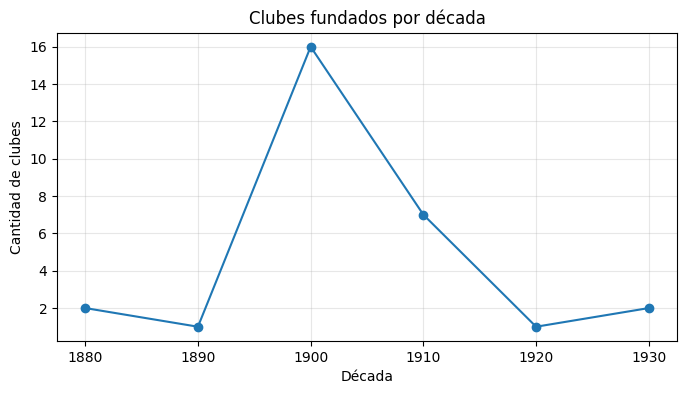

In [0]:
# Gráfico de líneas: clubes fundados por década
import matplotlib.pyplot as plt

pdf = g_decada.toPandas()
plt.figure(figsize=(8, 4))
plt.plot(pdf["decada"], pdf["clubes_fundados"], marker="o")
plt.title("Clubes fundados por década")
plt.xlabel("Década")
plt.ylabel("Cantidad de clubes")
plt.grid(True, alpha=0.3)
plt.show()

In [0]:
# Antigüedad promedio por región
display(df_delta.groupBy("region")
        .agg(F.round(F.avg("antiguedad"), 1).alias("antiguedad_promedio"))
        .orderBy(F.desc("antiguedad_promedio")))

region,antiguedad_promedio
Centro,119.4
Noroeste,115.5
Cuyo,112.3
Sin dato,108.0


Databricks visualization. Run in Databricks to view.

### Interpretación de resultados
- **Distribución geográfica:** Buenos Aires (9 clubes), CABA (8) y Santa Fe (4) concentran 21 de los 29 clubes analizados (alrededor del 72%). El resto se reparte entre Córdoba, Mendoza, San Juan, Tucumán y Santiago del Estero.
- **Época de fundación:** la década de 1900 es la más fuerte, con 16 de los 29 clubes. Le sigue la de 1910 con 7, y antes de 1900 se fundaron solo 3.
- **Antigüedad por región:** la región Centro tiene la antigüedad promedio más alta (119,4 años), seguida por Noroeste (115,5) y Cuyo (112,3). Las diferencias son chicas y Cuyo y Noroeste tienen pocos clubes (3 y 2), por lo que no conviene sacar conclusiones fuertes.
- **Limitaciones:** el dataset es una muestra de 30 clubes armada para el TP, no el universo completo del fútbol argentino. Un club se eliminó por no tener año de fundación y otro quedó sin región por no tener provincia.

## Etapa 6: Conclusión final
El TP recorrió un proceso ETL completo en Databricks: se extrajeron datos desde CSV, se limpiaron y transformaron con Spark (Python y SQL), se almacenaron en Delta Lake con validación de integridad y se analizaron mediante gráficos. Delta Lake permitió guardar los datos transformados de forma consistente y consultar su historial de versiones.

**Limitaciones:** el dataset es reducido y fue armado para el trabajo práctico. Los años de fundación deberían verificarse con fuentes oficiales si se quisiera usar esta información fuera del TP.